# Comparative Analysis of Run 1 vs Run 2 Detection Results

This notebook compares the detection probability scores between two runs (`run_1` and `run_2`) to determine if there are significant differences in detection performance or behavior.

**Metrics Comparison**:
- **Paired t-test**: Parametric test for differences in means.
- **Wilcoxon signed-rank test**: Non-parametric test for differences in distributions (recommended if data is not normal).

In [29]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Set display options
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

## 1. Load Data

In [30]:
# Define paths
run1_path = '../datasets/temperature_1/run_1/detection_results_run_1.csv'
run2_path = '../datasets/temperature_1/run_2/detection_results.csv'

# Load datasets
df1 = pd.read_csv(run1_path)
df2 = pd.read_csv(run2_path)

print(f"Run 1 Shape: {df1.shape}")
print(f"Run 2 Shape: {df2.shape}")

Run 1 Shape: (6346, 20)
Run 2 Shape: (6346, 20)


## 2. Preprocessing & Merging

We start by merging the datasets on `pr_id`, `variation` (context), and `model` to ensure we are comparing the exact same generated texts.

In [31]:
# Normalize identifiers if needed
df1['pr_id'] = df1['pr_id'].astype(str)
df2['pr_id'] = df2['pr_id'].astype(str)

# Select relevant columns for merging and comparison
cols_to_keep = ['pr_id', 'variation', 'model', 'entry_type', 'roberta_ai_probability', 'roberta-qa_ai_probability', 'zerogpt_ai_probability']

df1_subset = df1[cols_to_keep].copy()
df2_subset = df2[cols_to_keep].copy()

# Rename probability columns to distinguish runs
df1_subset = df1_subset.rename(columns={
    'roberta_ai_probability': 'roberta_run1',
    'roberta-qa_ai_probability': 'roberta_qa_run1',
    'zerogpt_ai_probability': 'zerogpt_run1'
})

df2_subset = df2_subset.rename(columns={
    'roberta_ai_probability': 'roberta_run2',
    'roberta-qa_ai_probability': 'roberta_qa_run2',
    'zerogpt_ai_probability': 'zerogpt_run2'
})

# Merge datasets
merged_df = pd.merge(
    df1_subset,
    df2_subset,
    on=['pr_id', 'variation', 'model', 'entry_type'],
    how='inner'
)

print(f"Merged Dataset Shape: {merged_df.shape}")
print(f"Skipped rows (unmatched): {len(df1) - len(merged_df)} from Run 1")
merged_df.head()

Merged Dataset Shape: (6346, 10)
Skipped rows (unmatched): 0 from Run 1


,pr_id,variation,model,entry_type,roberta_run1,roberta_qa_run1,zerogpt_run1,roberta_run2,roberta_qa_run2,zerogpt_run2
0,PR_kwDOAQ0TF85v-zYA,P-4,meta-llama/llama-3.1-70b-instruct,ai,0.011566,0.002711,0.0000,0.999066,0.999852,1.0000
1,MDExOlB1bGxSZXF1ZXN0ODg1NDg5NzE=,P-3,gpt-5-mini-2025-08-07,ai,0.016061,0.002950,0.0000,0.007777,0.004302,0.4974
2,PR_kwDOAQ0TF84uY3ik,P-4,gpt-5-mini-2025-08-07,ai,0.011147,0.000318,0.0000,0.002871,0.000988,0.0000
3,MDExOlB1bGxSZXF1ZXN0OTg0Nzg3NjI=,P-4,gpt-5-mini-2025-08-07,ai,0.000722,0.000309,0.4324,0.013868,0.000362,0.0000
4,PR_kwDOAQ0TF86NsRfY,P-2,meta-llama/llama-3.1-70b-instruct,ai,NaN,NaN,0.0000,NaN,NaN,0.5119


## 3. Statistical Analysis

We will compare the distributions of detection probabilities for each detector (`roberta`, `roberta-qa`, `zerogpt`) and each model.

**Hypothesis**:
- $H_0$: There is no significant difference in detection probabilities between Run 1 and Run 2.
- $H_1$: There is a significant difference.

In [35]:
def compare_runs(data, detector_name, run1_col, run2_col):
    results = []
    
    # Get unique models
    models = data['model'].unique()
    models = [m for m in models if m != 'human']

    print(f"\n--- Detailed Analysis for {detector_name} ---\n")
    
    for model in models:
        subset = data[data['model'] == model].dropna(subset=[run1_col, run2_col])
        
        if len(subset) < 2:
            continue
        
        diff = subset[run1_col] - subset[run2_col]
        
        # Normality test (Shapiro-Wilk)
        # If p > 0.05, assume normal distribution
        if len(diff) >= 3:
            shapiro_stat, shapiro_p = stats.shapiro(diff)
            is_normal = shapiro_p > 0.05
        else:
            is_normal = True # Fallback for tiny samples, though t-test is shaky
            
        # Paired t-test
        t_stat, t_p = stats.ttest_rel(subset[run1_col], subset[run2_col])
        
        # Wilcoxon signed-rank test
        # Handle cases where all diffs are zero (Wilcoxon fails)
        if np.allclose(diff, 0):
            wilcoxon_stat, wilcoxon_p = 0.0, 1.0
        else:
            wilcoxon_stat, wilcoxon_p = stats.wilcoxon(subset[run1_col], subset[run2_col])
        
        results.append({
            'Model': model,
            'Detector': detector_name,
            'N': len(subset),
            'Mean Diff (Run1 - Run2)': diff.mean(),
            'Std Diff': diff.std(),
            'Distribution': 'normal' if is_normal else 'not normal',
            # 'Shapiro p-value': shapiro_p if len(diff) >= 3 else np.nan,
            # 'Paired t-test p-value': t_p,
            'Wilcoxon p-value': wilcoxon_p,
            'Decision': 'Different' if (is_normal and t_p < 0.05) or (not is_normal and wilcoxon_p < 0.05) else 'Same'
        })
        
    return pd.DataFrame(results)

results_roberta = compare_runs(merged_df, 'roberta', 'roberta_run1', 'roberta_run2')
results_roberta_qa = compare_runs(merged_df, 'roberta-qa', 'roberta_qa_run1', 'roberta_qa_run2')
results_zerogpt = compare_runs(merged_df, 'zerogpt', 'zerogpt_run1', 'zerogpt_run2')

all_results = pd.concat([results_roberta, results_roberta_qa, results_zerogpt], ignore_index=True)
display(all_results)


--- Detailed Analysis for roberta ---


--- Detailed Analysis for roberta-qa ---


--- Detailed Analysis for zerogpt ---



,Model,Detector,N,Mean Diff (Run1 - Run2),Std Diff,Distribution,Wilcoxon p-value,Decision
0,meta-llama/llama-3.1-70b-instruct,roberta,631,-0.009262,0.474150,not normal,0.739217,Same
1,gpt-5-mini-2025-08-07,roberta,1990,0.001492,0.060594,not normal,0.276485,Same
2,Qwen/Qwen2.5-72B-Instruct,roberta,1797,0.011198,0.440012,not normal,0.475484,Same
3,meta-llama/llama-3.1-70b-instruct,roberta-qa,631,0.001336,0.489256,not normal,0.292630,Same
4,gpt-5-mini-2025-08-07,roberta-qa,1990,-0.000188,0.033534,not normal,0.344931,Same
5,Qwen/Qwen2.5-72B-Instruct,roberta-qa,1797,0.003370,0.507486,not normal,0.748877,Same
6,meta-llama/llama-3.1-70b-instruct,zerogpt,2004,0.006450,0.363193,not normal,0.418452,Same
7,gpt-5-mini-2025-08-07,zerogpt,2004,-0.009024,0.303587,not normal,0.162647,Same
8,Qwen/Qwen2.5-72B-Instruct,zerogpt,2004,-0.005469,0.405627,not normal,0.583265,Same


## 4. Visualization of Differences

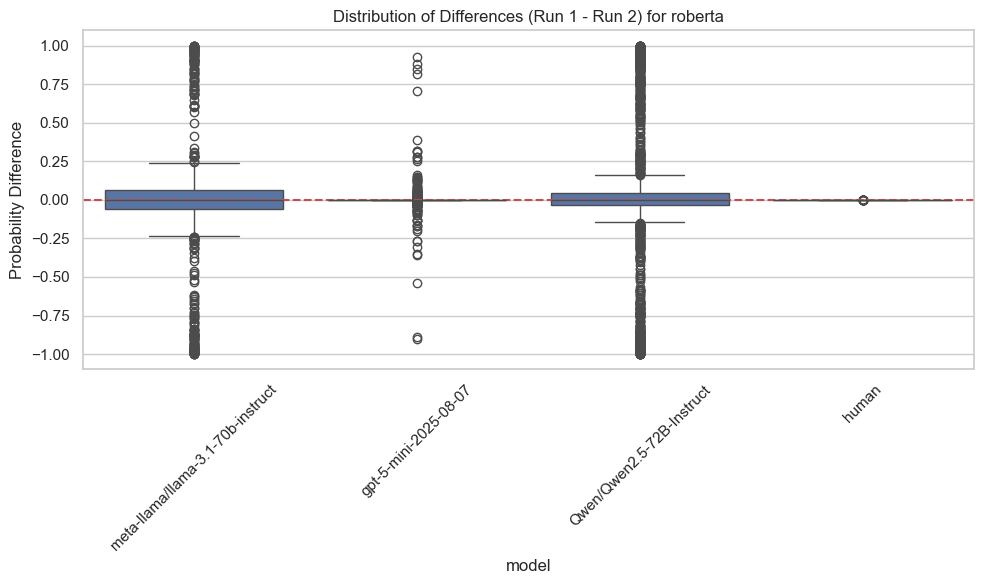

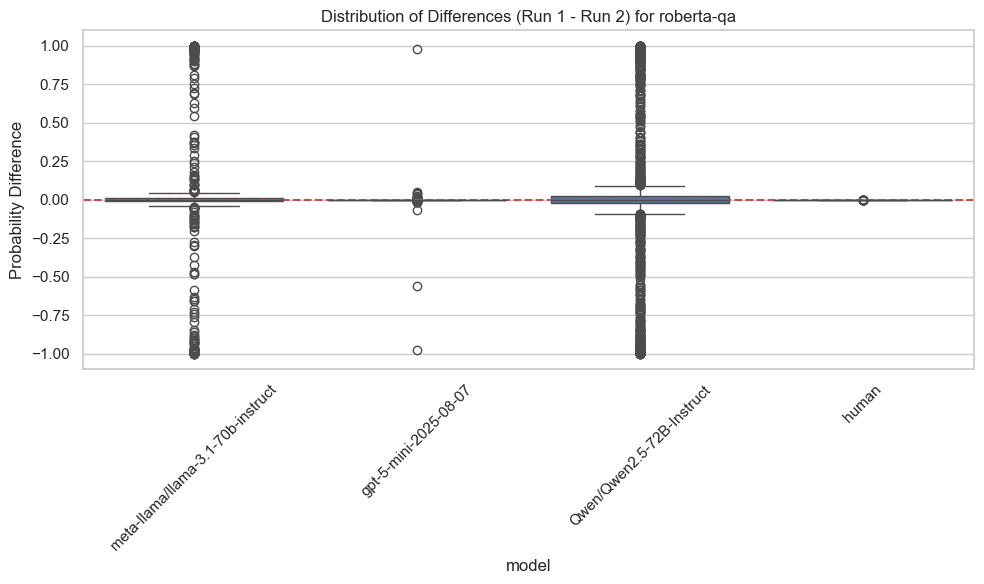

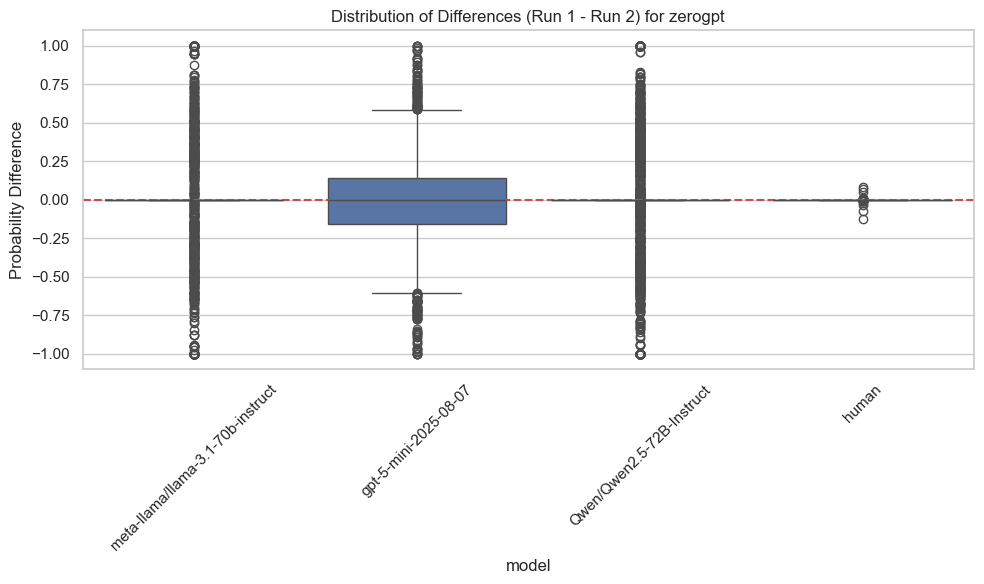

In [33]:
def plot_differences(data, detector_name, run1_col, run2_col):
    plt.figure(figsize=(10, 6))
    
    # Calculate differences
    data = data.copy()
    data['difference'] = data[run1_col] - data[run2_col]
    
    sns.boxplot(x='model', y='difference', data=data)
    plt.title(f'Distribution of Differences (Run 1 - Run 2) for {detector_name}')
    plt.axhline(0, color='r', linestyle='--')
    plt.ylabel('Probability Difference')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

plot_differences(merged_df, 'roberta', 'roberta_run1', 'roberta_run2')
plot_differences(merged_df, 'roberta-qa', 'roberta_qa_run1', 'roberta_qa_run2')
plot_differences(merged_df, 'zerogpt', 'zerogpt_run1', 'zerogpt_run2')

## 5. Conclusion

Based on the p-values from the table above:
- If **p-value < 0.05**, we reject the null hypothesis and conclude that there is a statistically significant difference between the runs.
- If **p-value >= 0.05**, we fail to reject the null hypothesis, suggesting the variation is likely due to chance or the models are consistent.